# UIUC graduation rates

This notebook summarizes university graduation outcomes and compares college trends across entering fall cohorts. The university line plot uses **non-cumulative** rates (graduation in a specified year). The college comparison uses **cumulative** rates (graduation by a specified year).

Note: I chose to investigate only 3-Year and 5-Year groups based on preliminary analysis after viewing the website's published Graduation Rates.

Source: https://dair.illinois.edu/access-data/retention-and-graduation-rates/


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
# from: https://www.uillinois.edu/erc/brand_and_marketing/brand/color_palettes
group_colors = {"3-Year": "#13294B", "5-Year": "#FF5F0F"}
# group_colors = {"3-Year": "#13294B", "5-Year": "#FF5F0F", "6-Year": "blue"}

university_rates = pd.read_csv(
    "Graduation_Rates_Non-Cumulative_Stacked_Bar.csv",
    encoding="utf-16",
    sep="\t",
    thousands=",",
)

university_rates

,Fall Cohort,Graduation Year Group,Graduate Count by Year Group,Graduation Rate by Year Group,Total Cases (NonCum Groupings),Total Cases,Total Grad Count Label (Year Group),Total Grad Rate Label (Year Group),Cohort Data Status
0,2008 Cohort,6-Year,153.0,0.021118,7245.0,NaN,NaN,NaN,Final
1,2008 Cohort,5-Year,934.0,0.128916,7245.0,NaN,NaN,NaN,Final
2,2008 Cohort,4-Year,4854.0,0.669979,7245.0,NaN,NaN,NaN,Final
3,2008 Cohort,3-Year,161.0,0.022222,7245.0,NaN,NaN,NaN,Final
4,2008 Cohort,NaN,NaN,NaN,NaN,7245.0,6102.0,0.842236,Final
...,...,...,...,...,...,...,...,...,...
60,2020 Cohort,6-Year,132.0,0.017683,7465.0,NaN,NaN,NaN,Final
61,2020 Cohort,5-Year,676.0,0.090556,7465.0,NaN,NaN,NaN,Final
62,2020 Cohort,4-Year,5178.0,0.693637,7465.0,NaN,NaN,NaN,Final
63,2020 Cohort,3-Year,362.0,0.048493,7465.0,NaN,NaN,NaN,Final


## University-wide graduation rate

The single metric below pools all 2008-2020 entering cohorts and calculates the overall graduation rate. It uses each cohort's summary row once (blank 'Graduation Year Group' entry), avoiding duplicate denominators in the graduation-year rows. 

In [2]:
# the csv stores each cohort's overall totals in the blank col (NaN) see df above
cohort_totals = university_rates.loc[university_rates["Graduation Year Group"].isna()].copy()

total_graduates = int(cohort_totals["Total Grad Count Label (Year Group)"].sum())
total_entrants = int(cohort_totals["Total Cases"].sum())
university_graduation_rate = total_graduates / total_entrants

display(Markdown(
    f"### {university_graduation_rate:.1%} university-wide graduation rate\n"
    f"calculated as **{total_graduates:,} graduates / {total_entrants:,} entrants** "
    "across the 2008-2020 entering cohorts, through the reported six-year window."
))

### 85.1% university-wide graduation rate
calculated as **80,697 graduates / 94,825 entrants** across the 2008-2020 entering cohorts, through the reported six-year window.

## Graduation in year three versus year five

Each line shows the percentage of the entering cohort graduating in the specified year, using the non-cumulative stacked-bar export. For example, about 4.8% of the overall Fall 2020 cohort graduated in the three-year group. The year-five line excludes those graduating in years three and four.

In [3]:
groups_to_plot = ["3-Year", "5-Year"]
# groups_to_plot = ["3-Year", "5-Year", "6-Year"]

selected_rows = university_rates.loc[university_rates["Graduation Year Group"].isin(groups_to_plot)]

cohorts = selected_rows.groupby(
  ["Fall Cohort", "Graduation Year Group"], as_index=False
  )["Graduation Rate by Year Group"].agg("mean")
# extract year from fall cohort string
cohorts["Cohort Year"] = cohorts["Fall Cohort"].str.split().str[0].astype(int)
cohorts = cohorts.sort_values(["Cohort Year", "Graduation Year Group"])
cohorts

,Fall Cohort,Graduation Year Group,Graduation Rate by Year Group,Cohort Year
0,2008 Cohort,3-Year,0.022222,2008
1,2008 Cohort,5-Year,0.128916,2008
2,2009 Cohort,3-Year,0.028744,2009
3,2009 Cohort,5-Year,0.123742,2009
4,2010 Cohort,3-Year,0.029412,2010
5,2010 Cohort,5-Year,0.132860,2010
6,2011 Cohort,3-Year,0.031492,2011
7,2011 Cohort,5-Year,0.127072,2011
8,2012 Cohort,3-Year,0.025919,2012
9,2012 Cohort,5-Year,0.123081,2012


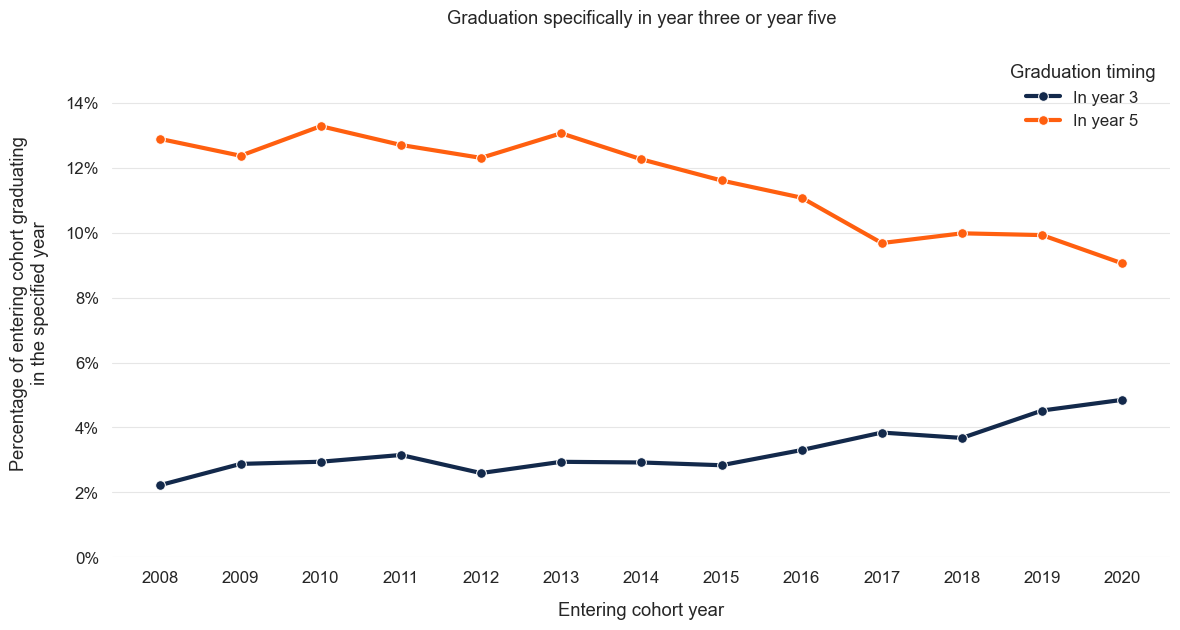

In [4]:
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.lineplot(
    data=cohorts,
    x="Cohort Year",
    y="Graduation Rate by Year Group",
    hue="Graduation Year Group",
    hue_order=groups_to_plot,
    palette=group_colors,
    marker="o",
    markersize=7,
    linewidth=3,
    estimator=None,
    ax=ax,
)
ax.set_title("Graduation specifically in year three or year five", loc="Center", pad=18)
ax.set_xlabel("Entering cohort year", labelpad=12)
ax.set_ylabel("Percentage of entering cohort graduating\nin the specified year", labelpad=12)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set_xticks(sorted(cohorts["Cohort Year"].unique()))
ax.set_ylim(0, cohorts["Graduation Rate by Year Group"].max() * 1.18)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)
# Use "in" to distinguish these rates from cumulative completion.
legend_handles, legend_labels = ax.get_legend_handles_labels()
ax.legend(legend_handles, ["In year 3", "In year 5"],
          title="Graduation timing", frameon=False, loc="upper right")
sns.despine(ax=ax, left=True, bottom=True)
fig.tight_layout()
fig.savefig("graduation_rates_line_plot.png", dpi=200, bbox_inches="tight")
plt.show()

Across entering cohorts from **2008 to 2020**, the share graduating in year three rose from about **2.2% to 4.8%**, while the share graduating **specifically in year five** fell from about **12.9% to 9.1%**. These are non-cumulative rates.

## Changes in cumulative graduation rates: 2008-2010 vs. 2018-2020 entering cohorts

This section uses the separate college exports. Their rates measure completion **by year three** and **by year five**; the five-year graduates include those graduating in years three and four. 

### How pooling works

For each college and graduation group, combine the **2008, 2009, and 2010 entering cohorts** into an early period and the **2018, 2019, and 2020 entering cohorts** into a recent period:


$R_{\mathrm{pooled}} = \frac{\sum(\text{grads across the three cohorts})}{\sum(\text
{of entrants across same three cohorts})}$

A cohort with 200 entrants therefore contributes twice as much weight as one with 100 entrants. We do not take a simple average of the three percentages. Using three cohorts reduces dependence on an individual year's result.

$\text{change in \% points} = 100 \times (R_{\mathrm{recent, pooled}} - R_{\mathrm{early, pooled}})$

NOTE: the analysis includes only the nine colleges with all 13 cohorts from 2008 through 2020. Thus, Social Work (2013-2020), Aviation (2008-2011), and Information Sciences (2020 only) are excluded from this comparison due to a lack of data. Aviation and some Social Work cohorts are also very small.

In [5]:
# mapping names from csv to clearer ones
college_columns = {
    "Compare": "College",
    "Compare Cohort v2": "Fall Cohort",
    "Graduation Rate Compare (Count)": "Graduates",
    "Graduation Rate Compare": "Rate",
    "Total Cases": "Entrants",
}

# for groups 3 and 5 separately
college_frames = []

for grp in [3, 5]:
    filename = f"{grp}-year-Graduation-Rates-Bar-Chart_data.csv"
    college_data = pd.read_csv(filename)
    college_data = college_data.rename(columns=college_columns)

    # extract str from fall cohort col
    cohort_year = college_data["Fall Cohort"].str.split().str[0]
    college_data["Cohort Year"] = cohort_year.astype(int)
    college_data["Graduation Group"] = f"{grp}-Year"
    college_frames.append(college_data)

# Stack both files into one table and reset the row numbers.
college_rates = pd.concat(college_frames, ignore_index=True)

# Show entering-cohort sizes side by side for the two groups.
# so resulting rows will be college X graduation groups = 130
entrants_by_grp = college_rates.pivot(
    index=["College", "Cohort Year"],
    columns="Graduation Group",
    values="Entrants",
)

# True means both groups use the same entering-cohort size,
# which should be true here since 3 year is nested in 5 year
entrants_by_grp["Same cohort size"] = (
    entrants_by_grp["3-Year"] == entrants_by_grp["5-Year"]
)
display(entrants_by_grp)

# Compare cumulative graduate counts with the university export.
count_comparisons = []

for grp in [3, 5]:
    # include year 3 for the 3-Year group, and years 3-5 for the 5-Year group (nested)
    included_years = [f"{year}-Year" for year in range(3, grp + 1)]
    university_rows = university_rates.loc[
        university_rates["Graduation Year Group"].isin(included_years)
    ]

    # Sum the included graduation years within each fall cohort.
    university_counts = university_rows.groupby("Fall Cohort")["Graduate Count by Year Group"].sum()

    # Sum graduates across colleges for the same graduation group.
    college_rows = college_rates.loc[college_rates["Graduation Group"] == f"{grp}-Year"]
    college_counts = college_rows.groupby("Fall Cohort")["Graduates"].sum()

    # Align university and college totals by fall cohort.
    comparison = pd.concat(
        [university_counts, college_counts],
        axis=1,
        keys=["University graduates", "College graduates"],
    )
    comparison["Graduation Group"] = f"{grp}-Year"
    comparison["Difference"] = (
        comparison["College graduates"] - comparison["University graduates"]
    )
    count_comparisons.append(comparison.reset_index())

# zero diffs mean the two sources agree (should be true for all)
graduate_count_comparison = pd.concat(count_comparisons, ignore_index=True)
display(graduate_count_comparison)

Graduation Group                                                3-Year  \
College                                            Cohort Year           
Agricultural, Consumer, & Environmental Science... 2008            503   
                                                   2009            492   
                                                   2010            453   
                                                   2011            433   
                                                   2012            482   
...                                                                ...   
School of Social Work (SSW)                        2016             59   
                                                   2017             50   
                                                   2018             51   
                                                   2019             50   
                                                   2020             59   

Graduation Group                                                5-Year  \
College                                            Cohort Year           
Agricultural, Consumer, & Environmental Science... 2008            503   
                                                   2009            492   
                                                   2010            453   
                                                   2011            433   
                                                   2012            482   
...                                                                ...   
School of Social Work (SSW)                        2016             59   
                                                   2017             50   
                                                   2018             51   
                                                   2019             50   
                                                   2020             59   

Graduation Group                                                Same cohort size  
College                                            Cohort Year                    
Agricultural, Consumer, & Environmental Science... 2008                     True  
                                                   2009                     True  
                                                   2010                     True  
                                                   2011                     True  
                                                   2012                     True  
...                                                                          ...  
School of Social Work (SSW)                        2016                     True  
                                                   2017                     True  
                                                   2018                     True  
                                                   2019                     True  
                                                   2020                     True  

[130 rows x 3 columns]

,Fall Cohort,University graduates,College graduates,Graduation Group,Difference
0,2008 Cohort,161.0,161,3-Year,0.0
1,2009 Cohort,200.0,200,3-Year,0.0
2,2010 Cohort,203.0,203,3-Year,0.0
3,2011 Cohort,228.0,228,3-Year,0.0
4,2012 Cohort,179.0,179,3-Year,0.0
5,2013 Cohort,215.0,215,3-Year,0.0
6,2014 Cohort,202.0,202,3-Year,0.0
7,2015 Cohort,214.0,214,3-Year,0.0
8,2016 Cohort,250.0,250,3-Year,0.0
9,2017 Cohort,288.0,288,3-Year,0.0


In [6]:
# Keep the same nine units used in the original comparison.
cohort_coverage = college_rates.groupby("College")["Cohort Year"].agg(
    first="min", last="max", count="nunique"
)
complete_colleges = cohort_coverage.index[
    (cohort_coverage["first"] == 2008)
    & (cohort_coverage["last"] == 2020)
    & (cohort_coverage["count"] == 13)
]
complete_rates = college_rates.loc[
    college_rates["College"].isin(complete_colleges)
].copy()

# Select the two periods; intervening cohorts are not pooled into either period.
early_cohorts = complete_rates.loc[
    complete_rates["Cohort Year"].between(2008, 2010)
].copy()
early_cohorts["Period"] = "2008-2010"

recent_cohorts = complete_rates.loc[
    complete_rates["Cohort Year"].between(2018, 2020)
].copy()
recent_cohorts["Period"] = "2018-2020"

period_cohorts = pd.concat([early_cohorts, recent_cohorts], ignore_index=True)
pooled_rates = period_cohorts.groupby(
    ["College", "Graduation Group", "Period"], as_index=False
)[["Graduates", "Entrants"]].sum()
# using same formula as earlier
pooled_rates["Pooled Rate"] = pooled_rates["Graduates"] / pooled_rates["Entrants"]

# compare the recent and early rates at each graduation group
period_comparison = pooled_rates.pivot(
    index=["College", "Graduation Group"],
    columns="Period",
    values="Pooled Rate",
)
# using the same formula as earlier
period_comparison["Change (pp)"] = 100 * (
    period_comparison["2018-2020"] - period_comparison["2008-2010"]
)

period_comparison

Period                                                               2008-2010  \
College                                            Graduation Group              
Agricultural, Consumer, & Environmental Science... 3-Year             0.021409   
                                                   5-Year             0.848066   
Applied Health Sciences (AHS)                      3-Year             0.022082   
                                                   5-Year             0.832808   
College of Media                                   3-Year             0.033679   
                                                   5-Year             0.873057   
Division of Explatory Studies (DES)                3-Year             0.011712   
                                                   5-Year             0.802908   
Education                                          3-Year             0.004310   
                                                   5-Year             0.903017   
Fine & Applied Arts (FAA)                          3-Year             0.005177   
                                                   5-Year             0.819672   
Gies College of Business                           3-Year             0.071192   
                                                   5-Year             0.900110   
Grainger College of Engineering                    3-Year             0.021241   
                                                   5-Year             0.792421   
Liberal Arts & Sciences (LAS)                      3-Year             0.036829   
                                                   5-Year             0.840958   

Period                                                               2018-2020  \
College                                            Graduation Group              
Agricultural, Consumer, & Environmental Science... 3-Year             0.043279   
                                                   5-Year             0.835410   
Applied Health Sciences (AHS)                      3-Year             0.040314   
                                                   5-Year             0.820829   
College of Media                                   3-Year             0.046632   
                                                   5-Year             0.862694   
Division of Explatory Studies (DES)                3-Year             0.015415   
                                                   5-Year             0.760405   
Education                                          3-Year             0.011338   
                                                   5-Year             0.875283   
Fine & Applied Arts (FAA)                          3-Year             0.016575   
                                                   5-Year             0.803867   
Gies College of Business                           3-Year             0.050364   
                                                   5-Year             0.916620   
Grainger College of Engineering                    3-Year             0.042624   
                                                   5-Year             0.869829   
Liberal Arts & Sciences (LAS)                      3-Year             0.065789   
                                                   5-Year             0.842671   

Period                                                               Change (pp)  
College                                            Graduation Group               
Agricultural, Consumer, & Environmental Science... 3-Year               2.186985  
                                                   5-Year              -1.265646  
Applied Health Sciences (AHS)                      3-Year               1.823153  
                                                   5-Year              -1.197890  
College of Media                                   3-Year               1.295337  
                                                   5-Year              -1.036269  
Division of Explatory Studies (DES)                3-Y

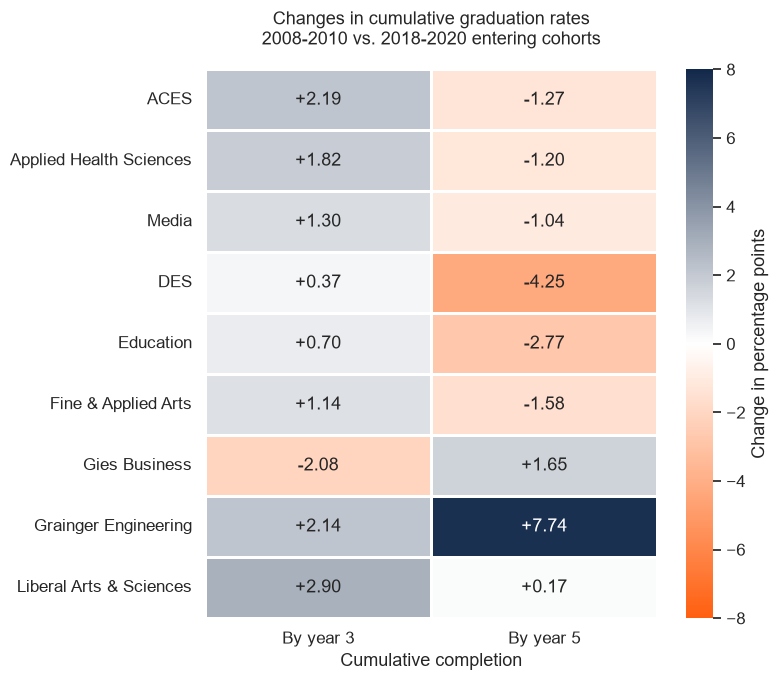

In [93]:
college_changes = period_comparison["Change (pp)"].unstack("Graduation Group")
college_labels = {
    "Agricultural, Consumer, & Environmental Sciences (ACES)": "ACES",
    "Applied Health Sciences (AHS)": "Applied Health Sciences",
    "College of Media": "Media",
    "Division of Explatory Studies (DES)": "DES",
    "Fine & Applied Arts (FAA)": "Fine & Applied Arts",
    "Gies College of Business": "Gies Business",
    "Grainger College of Engineering": "Grainger Engineering",
    "Liberal Arts & Sciences (LAS)": "Liberal Arts & Sciences",
}

change_colors = LinearSegmentedColormap.from_list(
    "orange_white_blue", ["#FF5F0F", "#FFFFFF", "#13294B"]
)

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    college_changes.rename(index=college_labels),
    annot=True,
    fmt="+.2f",
    center=0,
    cmap=change_colors,
    vmin=-8,
    vmax=8,
    linewidths=2,
    cbar_kws={"label": "Change in percentage points"},
    ax=ax,
)
ax.set_title(
    "Changes in cumulative graduation rates\n"
    "2008-2010 vs. 2018-2020 entering cohorts",
    pad=18,
)
# Use "by" because these groups include earlier graduates.
ax.set_xticklabels(["By year 3", "By year 5"])
ax.set_xlabel("Cumulative completion")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
fig.savefig("college_graduation_changes.png", dpi=200, bbox_inches="tight")
plt.show()